# Vision Transformer - reprodukcja wyniku

**Przedmiot:** Analiza danych obrazowych i multimedialnych

**Temat 6:** Vision Transformer

> A. Dosovitskiy i in., *An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale*, ICLR 2021 (arXiv:2010.11929).
> Kod autorów: [google-research/vision_transformer](https://github.com/google-research/vision_transformer), licencja Apache-2.0.

**Centralne twierdzenie artykułu:** zwykły transformer, bez splotów, zastosowany bezpośrednio do sekwencji fragmentów obrazu (patchy), po pretrainingu na dużym zbiorze danych dorównuje najlepszym sieciom splotowym w klasyfikacji obrazów.

**Zakres notatnika:**

- weryfikacja przygotowania tokenów i wymiarów reprezentacji: własne przejście przez model na oficjalnych wagach (sekcje 5-7),
- fine-tuning ViT-B/32 i ViT-B/16 na CIFAR-10 i CIFAR-100 i porównanie z Tabelą 5 artykułu (sekcje 8-10),
- plan eksperymentów własnych (sekcja 11).

**Sprzęt i czas:** RTX 4070 Ti SUPER 16 GB. Pełny przebieg od zera ok. 50 min (głównie sekcja 8), z zapisanymi wynikami fine-tuningu ok. 2 min.

## 1. Środowisko

Notatnik uruchamiano na **Pythonie 3.10.12** (Linux / WSL2).

| Biblioteka | Wersja | Zastosowanie |
|---|---|---|
| `torch` | 2.6.0 (+cu118) | tensory, modele, trening |
| `torchvision` | 0.21.0 | transformacje obrazu |
| `timm` | 1.0.31 | implementacja ViT i oryginalne wagi autorów |
| `transformers` | 5.20.2 | checkpointy z karty projektu (`google/vit-*`) do sprawdzenia zgodności |
| `scikit-learn` | 1.7.2 | podział danych, kontrola metryk |
| `pyarrow`, `pandas` | 25.0.1, 2.3.3 | dane CIFAR (pliki Parquet), tabele |
| `matplotlib` | 3.10.9 | wykresy |

`torch` z obsługą CUDA trzeba zainstalować wcześniej, z indeksem dobranym do sterownika karty. Pozostałe biblioteki instaluje komórka poniżej.

In [2]:
%pip install -q timm==1.0.31 transformers==5.20.2 scikit-learn==1.7.2 pyarrow==25.0.1 pandas==2.3.3 matplotlib==3.10.9

import importlib.metadata
import platform

import torch

print(f"Python {platform.python_version()}")
for package in ["torch", "torchvision", "timm", "transformers", "scikit-learn", "pyarrow", "pandas", "matplotlib"]:
    print(f"{package:14s} {importlib.metadata.version(package)}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}, CUDA {torch.version.cuda}")

Note: you may need to restart the kernel to use updated packages.
Python 3.10.12
torch          2.6.0+cu118
torchvision    0.21.0+cu118
timm           1.0.31
transformers   5.20.2
scikit-learn   1.7.2
pyarrow        25.0.1
pandas         2.3.3
matplotlib     3.10.9
GPU: NVIDIA GeForce RTX 4070 Ti SUPER, CUDA 11.8


## 2. Konfiguracja

| Parametr | Znaczenie |
|---|---|
| `SEED` | ziarno losowości |
| `VAL_FRACTION` | część zbioru treningowego wydzielona jako walidacja do wyboru współczynnika uczenia (2%, jak u autorów) |
| `IMG_SIZE` | rozdzielczość wejścia modelu, do której skalowane są obrazy 32×32 |
| `MODELS` | checkpointy z karty projektu: identyfikator w `timm` i odpowiadający mu na Hugging Face |
| `FT_*` | protokół fine-tuningu (sekcja 8): efektywny batch 512 liczony w porcjach po 128, liczba kroków, siatka współczynników uczenia, momentum i obcinanie gradientu |
| `CACHE_DIR`, `RETRAIN` | wagi po fine-tuningu są zapisywane w `cache/`; przy `RETRAIN = False` są wczytywane zamiast trenowane od nowa |

Na GPU wyłączamy format TF32, żeby porównania z implementacją referencyjną w sekcjach 4-7 były w pełnej precyzji float32.

In [3]:
import gc
import io
import json
import os
import random
import time
import warnings
from pathlib import Path

os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
warnings.filterwarnings("ignore", message="IProgress not found")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import timm
import torch.nn.functional as F
from huggingface_hub import hf_hub_download
from huggingface_hub.utils import logging as hf_logging
from PIL import Image
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from torchvision.transforms import InterpolationMode, v2

hf_logging.set_verbosity_error()

SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_DIR = Path.cwd() / "data"
CACHE_DIR = Path.cwd() / "cache"
DATA_DIR.mkdir(exist_ok=True)
CACHE_DIR.mkdir(exist_ok=True)

DATASETS = ["cifar10", "cifar100"]
VAL_FRACTION = 0.02
IMG_SIZE = 224
BATCH_SIZE = 128
NUM_WORKERS = 0 if os.name == "nt" else 4

MODELS = {
    # nazwa: (checkpoint w timm, checkpoint z karty projektu na Hugging Face)
    "ViT-B/32": ("vit_base_patch32_224.orig_in21k", "google/vit-base-patch32-224-in21k"),
    "ViT-B/16": ("vit_base_patch16_224.orig_in21k", "google/vit-base-patch16-224-in21k"),
}

RETRAIN = False
FT_BATCH = 512
FT_MICRO_BATCH = 128
FT_STEPS = 500
FT_SEARCH_STEPS = 100
FT_LR_GRID = [0.001, 0.003, 0.01, 0.03]
FT_MOMENTUM = 0.9
FT_GRAD_CLIP = 1.0

torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


seed_everything(SEED)
print(f"Urządzenie: {DEVICE}")

Urządzenie: cuda


## 3. Dane

**CIFAR-10** i **CIFAR-100** (A. Krizhevsky, 2009): po 60 000 obrazów 32×32 RGB, podzielonych na 50 000 treningowych i 10 000 testowych; 10 klas po 6000 obrazów albo 100 klas po 600 obrazów. Pliki pobieramy z kopii udostępnionej na Hugging Face przez Uniwersytet w Toronto (`uoft-cs/cifar10`, `uoft-cs/cifar100`, przypięte wersje). Oryginalny serwer `cs.toronto.edu` bywa bardzo wolny.

Z oficjalnego zbioru treningowego wydzielamy warstwowo 2% jako walidację, jak autorzy (Appendix B.1.1). Służy ona tylko do wyboru współczynnika uczenia; końcowy model uczymy na całym zbiorze treningowym, a zbiór testowy służy wyłącznie do końcowej oceny.

In [4]:
HF_CIFAR = {
    # zbiór: (repozytorium, przypięta wersja, katalog, kolumna etykiety)
    "cifar10": ("uoft-cs/cifar10", "0b2714987fa478483af9968de7c934580d0bb9a2", "plain_text", "label"),
    "cifar100": ("uoft-cs/cifar100", "aadb3af77e9048adbea6b47c21a81e47dd092ae5", "cifar100", "fine_label"),
}


def load_cifar(name, split):
    repo, revision, subdir, label_column = HF_CIFAR[name]
    path = hf_hub_download(repo, f"{subdir}/{split}-00000-of-00001.parquet", repo_type="dataset",
                           revision=revision, local_dir=DATA_DIR / name)
    table = pq.read_table(path)
    images = np.stack([np.array(Image.open(io.BytesIO(item["bytes"])).convert("RGB"))
                       for item in table.column("img").to_pylist()])
    labels = np.array(table.column(label_column).to_pylist())
    classes = json.loads(table.schema.metadata[b"huggingface"])["info"]["features"][label_column]["names"]
    classes = ["crab" if label == "cra" else label for label in classes]   # literówka w metadanych kopii
    return images, labels, classes


DATA = {}
for name in DATASETS:
    train_images, train_labels, classes = load_cifar(name, "train")
    test_images, test_labels, _ = load_cifar(name, "test")
    train_idx, val_idx = train_test_split(np.arange(len(train_labels)), test_size=VAL_FRACTION,
                                          stratify=train_labels, random_state=SEED)
    DATA[name] = {
        "classes": classes,
        "train": (train_images[train_idx], train_labels[train_idx]),
        "val": (train_images[val_idx], train_labels[val_idx]),
        "test": (test_images, test_labels),
    }
    print(f"{name}: {len(classes)} klas, trening {len(train_idx)}, walidacja {len(val_idx)}, "
          f"test {len(test_labels)}, obraz {train_images.shape[1:]}")

cifar10: 10 klas, trening 49000, walidacja 1000, test 10000, obraz (32, 32, 3)
cifar100: 100 klas, trening 49000, walidacja 1000, test 10000, obraz (32, 32, 3)


### Preprocessing

Preprocessing musi być taki sam jak przy pretrainingu checkpointu (sprawdzamy to w jego konfiguracji): skalowanie 32×32 → 224×224 interpolacją dwusześcienną na obrazie `uint8` i normalizacja z **mean = std = 0.5**, czyli do zakresu [-1, 1], a nie statystykami ImageNetu. Skalujemy cały obraz, bez wycinania środka, które `timm` stosuje na ImageNecie, bo przy obrazach 32×32 obcięłoby fragment obiektu.

Skalowanie dodaje tokeny, ale nie informację: przy ViT-B/16 jeden patch 16×16 odpowiada fragmentowi ok. 2,3×2,3 piksela oryginału.

Batch po preprocessingu: (8, 3, 224, 224), zakres [-1.00, 1.00]


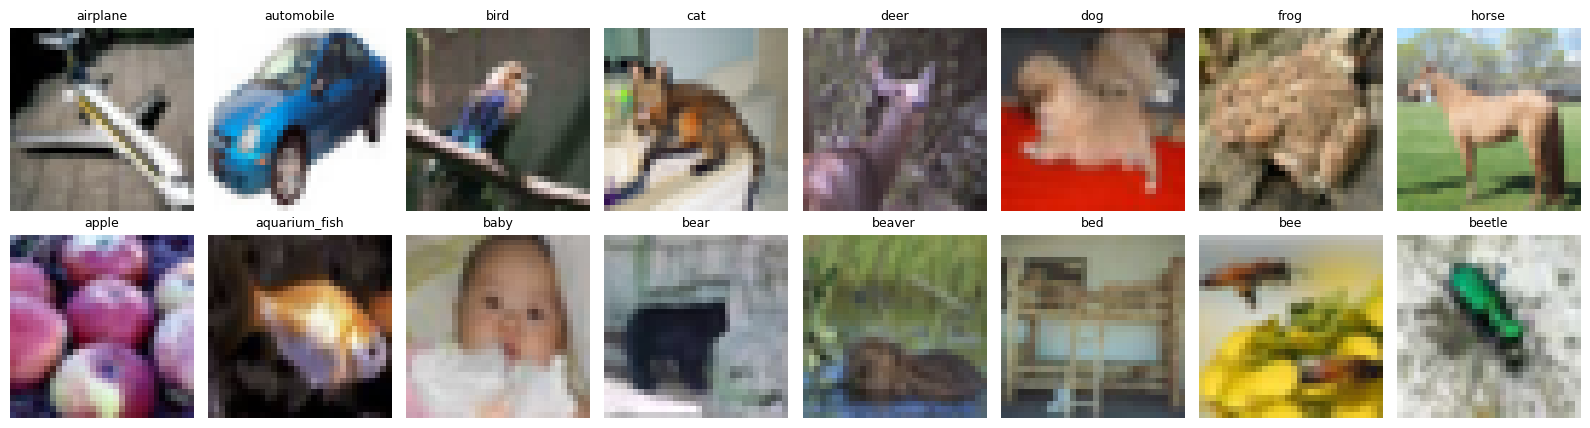

In [5]:
NORM_MEAN = NORM_STD = (0.5, 0.5, 0.5)
for timm_id, _ in MODELS.values():
    config = timm.models.get_pretrained_cfg(timm_id)
    assert config.mean == NORM_MEAN and config.std == NORM_STD and config.interpolation == "bicubic"


class CifarDataset(Dataset):
    def __init__(self, images, labels, transform):
        self.images, self.labels, self.transform = images, labels, transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return self.transform(torch.from_numpy(self.images[index]).permute(2, 0, 1)), int(self.labels[index])


def make_transform(img_size=IMG_SIZE, mean=NORM_MEAN, std=NORM_STD):
    return v2.Compose([
        v2.Resize((img_size, img_size), interpolation=InterpolationMode.BICUBIC, antialias=True),
        v2.ToDtype(torch.float32, scale=True),
        v2.Normalize(mean=mean, std=std),
    ])


def make_loader(images, labels, transform, batch_size=BATCH_SIZE, **kwargs):
    return DataLoader(CifarDataset(images, labels, transform), batch_size=batch_size,
                      num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda", **kwargs)


sample_images, _ = next(iter(make_loader(*DATA["cifar10"]["test"], make_transform(), batch_size=8)))
print(f"Batch po preprocessingu: {tuple(sample_images.shape)}, "
      f"zakres [{sample_images.min():.2f}, {sample_images.max():.2f}]")

fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
for row, name in enumerate(DATASETS):
    images, labels = DATA[name]["train"]
    for column in range(8):
        axes[row, column].imshow(images[np.flatnonzero(labels == column)[0]])
        axes[row, column].set_title(DATA[name]["classes"][column], fontsize=9)
        axes[row, column].axis("off")
plt.tight_layout()
plt.show()

## 4. Modele i wagi

Używamy dwóch checkpointów z artykułu, pretrenowanych na **ImageNet-21k** (ok. 14 mln obrazów, 21 843 klasy) w rozdzielczości 224×224, które różnią się tylko rozmiarem patcha: **ViT-B/32** i **ViT-B/16**. Wczytujemy je przez `timm`, które zawiera implementację ViT i port oryginalnych wag autorów (JAX/Flax).

Checkpointy mają wyzerowaną głowę klasyfikacyjną, więc wczytujemy je z `num_classes=0`: model zwraca wtedy embedding tokenu CLS o wymiarze D, a głowę dla klas CIFAR uczymy w sekcji 8. Sprawdzamy też, że struktura modeli zgadza się z Tabelą 1 artykułu (wariant Base: 12 warstw, D = 768, MLP 3072, 12 głów, 86 mln parametrów).

In [6]:
def load_vit(name, device="cpu", num_classes=0, **kwargs):
    # kwargs trafiają do timm.create_model, np. img_size=384 (timm interpoluje wtedy embedding pozycyjny)
    model = timm.create_model(MODELS[name][0], pretrained=True, num_classes=num_classes, **kwargs)
    return model.to(device).eval()


def free_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


rows = []
for name in MODELS:
    model = load_vit(name)
    patch, img = model.patch_embed.patch_size[0], model.patch_embed.img_size[0]
    row = {
        "model": name, "patch": patch, "siatka": f"{img // patch}×{img // patch}",
        "tokeny (z CLS)": model.patch_embed.num_patches + 1, "D": model.embed_dim,
        "warstwy": len(model.blocks), "głowy": model.blocks[0].attn.num_heads,
        "MLP": model.blocks[0].mlp.fc1.out_features,
        "parametry [M]": round(sum(p.numel() for p in model.parameters()) / 1e6, 1),
    }
    assert (row["warstwy"], row["D"], row["MLP"], row["głowy"]) == (12, 768, 3072, 12), "niezgodne z Tabelą 1"
    rows.append(row)
    del model
    free_memory()
pd.DataFrame(rows).set_index("model")

,patch,siatka,tokeny (z CLS),D,warstwy,głowy,MLP,parametry [M]
model,,,,,,,,
ViT-B/32,32,7×7,50,768,12,12,3072,87.5
ViT-B/16,16,14×14,197,768,12,12,3072,85.8


## 5. Blok 1: patch embedding, obraz jako sekwencja tokenów

Na prawdziwym obrazie z CIFAR-10 i wagach ViT-B/16 przechodzimy krok po kroku od obrazu do macierzy tokenów i sprawdzamy (`torch.allclose`), że każdy krok daje to samo co `timm`. Ten etap opisuje równanie (1) artykułu:

$$\mathbf{z}_0 = [\,\mathbf{x}_\text{class};\ \mathbf{x}_p^1\mathbf{E};\ \dots;\ \mathbf{x}_p^N\mathbf{E}\,] + \mathbf{E}_{pos}, \qquad \mathbf{E} \in \mathbb{R}^{(P^2 \cdot C) \times D},\ \ \mathbf{E}_{pos} \in \mathbb{R}^{(N+1) \times D}$$

gdzie $\mathbf{x}_p^i$ to spłaszczony $i$-ty patch, $P$ rozmiar patcha, $C = 3$ liczba kanałów, $N = HW/P^2$ liczba patchy, a $D$ wymiar modelu.

In [8]:
torch.set_grad_enabled(False)  # sekcje 5-7: tylko inferencja, przywracane na końcu sekcji 7

EXAMPLE_MODEL = "ViT-B/16"
vit = load_vit(EXAMPLE_MODEL, DEVICE)

example_raw = DATA["cifar10"]["test"][0][0]                                   # 32×32×3, uint8
example_class = DATA["cifar10"]["classes"][DATA["cifar10"]["test"][1][0]]
x = sample_images[:1].to(DEVICE)                                             # ten sam obraz po preprocessingu

P = vit.patch_embed.patch_size[0]
D = vit.embed_dim
IMG = x.shape[-1]
GRID = IMG // P
N_PATCHES = GRID * GRID

print(f"Model: {EXAMPLE_MODEL}, przykładowy obraz: '{example_class}'")
print(f"Wejście x: {tuple(x.shape)}  (batch, kanały C, wysokość H, szerokość W)")
print(f"P = {P}, D = {D}, siatka {GRID}×{GRID} → N = {N_PATCHES} patchy")

Model: ViT-B/16, przykładowy obraz: 'cat'
Wejście x: (1, 3, 224, 224)  (batch, kanały C, wysokość H, szerokość W)
P = 16, D = 768, siatka 14×14 → N = 196 patchy


### 5.1 Podział obrazu na patche

Obraz 224×224 dzielimy na nienachodzące kwadraty 16×16, czyli siatkę 14×14 = 196 patchy, numerowanych wierszami: obraz staje się **sekwencją**, jak zdanie złożone ze słów. Każdy patch spłaszczamy do wektora o długości $16 \cdot 16 \cdot 3 = 768$.

Patche: (1, 196, 768)  (batch, N, P·P·C)


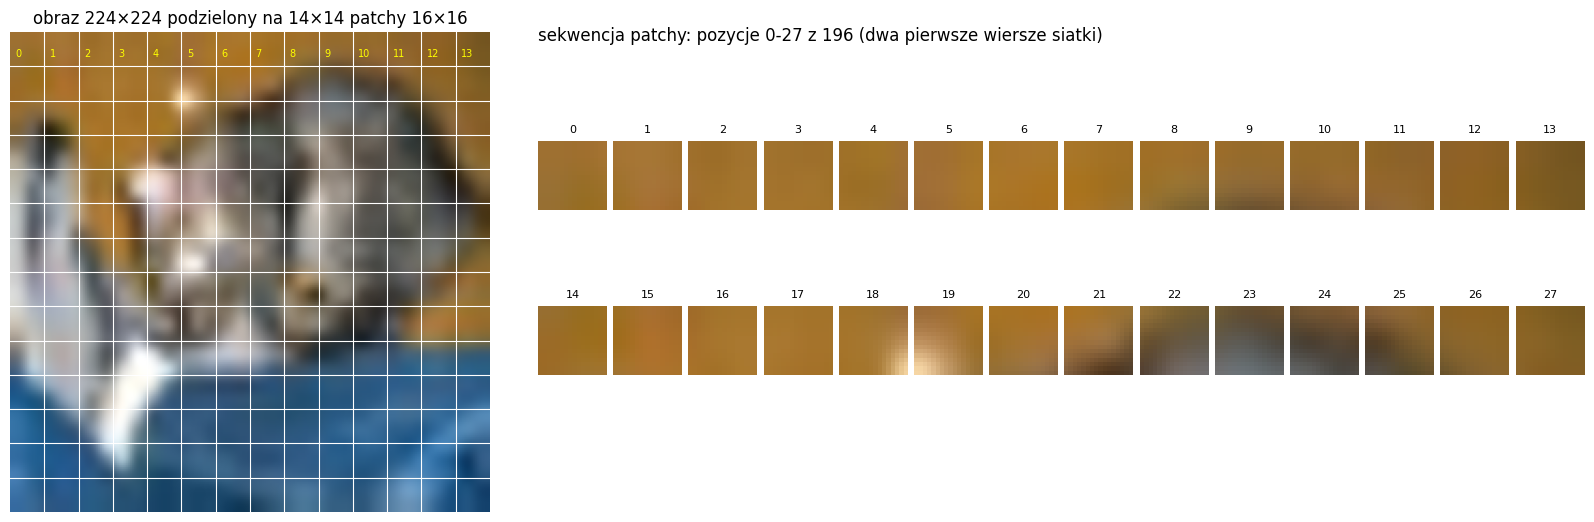

In [9]:
def patchify(images, patch):
    # (B, C, H, W) -> (B, N, C·P·P): patche numerowane wierszami, spłaszczone w kolejności (kanał, wiersz, kolumna)
    batch, channels, height, width = images.shape
    grid_h, grid_w = height // patch, width // patch
    patches = images.reshape(batch, channels, grid_h, patch, grid_w, patch)
    patches = patches.permute(0, 2, 4, 1, 3, 5)                               # (B, gh, gw, C, P, P)
    return patches.reshape(batch, grid_h * grid_w, channels * patch * patch)


patches = patchify(x, P)
print(f"Patche: {tuple(patches.shape)}  (batch, N, P·P·C)")
assert patches.shape == (1, N_PATCHES, 3 * P * P)


def to_display(image_chw):
    # odwrócenie normalizacji (x·std + mean) do zakresu [0, 1] na potrzeby wykresu
    std = torch.tensor(NORM_STD, device=image_chw.device).view(3, 1, 1)
    mean = torch.tensor(NORM_MEAN, device=image_chw.device).view(3, 1, 1)
    return (image_chw * std + mean).clamp(0, 1).permute(1, 2, 0).cpu().numpy()


fig = plt.figure(figsize=(16, 5.5))
grid_axis = fig.add_axes([0.0, 0.05, 0.3, 0.9])
grid_axis.imshow(to_display(x[0]))
for line in range(1, GRID):
    grid_axis.axhline(line * P - 0.5, color="white", linewidth=0.8)
    grid_axis.axvline(line * P - 0.5, color="white", linewidth=0.8)
for index in range(GRID):
    grid_axis.text(index * P + 2, 11, str(index), color="yellow", fontsize=7)
grid_axis.set_title(f"obraz {IMG}×{IMG} podzielony na {GRID}×{GRID} patchy {P}×{P}")
grid_axis.axis("off")

SHOWN = 2 * GRID   # dwa pierwsze wiersze siatki jako sekwencja
for position in range(SHOWN):
    axis = fig.add_axes([0.33 + (position % GRID) * 0.047, 0.55 - (position // GRID) * 0.3, 0.043, 0.25])
    patch_image = patches[0, position].reshape(3, P, P)
    axis.imshow(to_display(patch_image))
    axis.set_title(str(position), fontsize=8)
    axis.axis("off")
fig.text(0.33, 0.92, f"sekwencja patchy: pozycje 0-{SHOWN - 1} z {N_PATCHES} (dwa pierwsze wiersze siatki)", fontsize=12)
plt.show()

### 5.2 Projekcja liniowa: patch → token

Każdy spłaszczony patch mnożymy przez tę samą macierz $\mathbf{E}$ i dostajemy wektor o wymiarze $D$: **token**. W kodzie autorów projekcja jest zapisana jako splot `Conv2d` z jądrem i krokiem równym $P$, co jest tą samą operacją: te same wagi przykładane do każdego patcha osobno.

In [10]:
E = vit.patch_embed.proj.weight.reshape(D, -1)          # wagi splotu (D, C, P, P) -> macierz (D, C·P·P)
E_bias = vit.patch_embed.proj.bias
tokens_manual = patches @ E.T + E_bias                  # (1, N, D)
tokens_model = vit.patch_embed(x)                       # Conv2d(kernel=P, stride=P) + spłaszczenie

print(f"Wagi splotu: {tuple(vit.patch_embed.proj.weight.shape)} -> macierz E^T: {tuple(E.T.shape)}")
print(f"Tokeny (nasze):  {tuple(tokens_manual.shape)}")
print(f"Tokeny (model):  {tuple(tokens_model.shape)}")
print(f"max |różnica| = {(tokens_manual - tokens_model).abs().max().item():.1e}")
assert torch.allclose(tokens_manual, tokens_model, atol=1e-4)

Wagi splotu: (768, 3, 16, 16) -> macierz E^T: (768, 768)
Tokeny (nasze):  (1, 196, 768)
Tokeny (model):  (1, 196, 768)
max |różnica| = 5.2e-06


### 5.3 Token CLS i embedding pozycyjny

Na początek sekwencji dokładamy wyuczony **token CLS**, który przez kolejne warstwy zbiera informację z całego obrazu (sekcja 7). Self-attention nie zależy od kolejności tokenów, więc do każdego tokenu dodajemy wyuczony **embedding pozycyjny**, osobny dla każdej z $N + 1 = 197$ pozycji.

In [11]:
cls_token = vit.cls_token                    # (1, 1, D)
pos_embed = vit.pos_embed                    # (1, N + 1, D)
z0_manual = torch.cat([cls_token.expand(len(x), -1, -1), tokens_manual], dim=1) + pos_embed

# w timm: patch_embed -> _pos_embed (CLS + pozycje) -> patch_drop i norm_pre (w tych checkpointach puste)
assert isinstance(vit.patch_drop, torch.nn.Identity) and isinstance(vit.norm_pre, torch.nn.Identity)
z0_model = vit._pos_embed(tokens_model)

print(f"Token CLS:            {tuple(cls_token.shape)}")
print(f"Embedding pozycyjny:  {tuple(pos_embed.shape)}")
print(f"z0 (nasze):           {tuple(z0_manual.shape)}  = 1 token CLS + {N_PATCHES} tokenów patchy")
print(f"max |różnica| z modelem = {(z0_manual - z0_model).abs().max().item():.1e}")
assert z0_manual.shape == (1, N_PATCHES + 1, D)
assert torch.allclose(z0_manual, z0_model, atol=1e-4)

Token CLS:            (1, 1, 768)
Embedding pozycyjny:  (1, 197, 768)
z0 (nasze):           (1, 197, 768)  = 1 token CLS + 196 tokenów patchy
max |różnica| z modelem = 5.2e-06


### 5.4 Liczba tokenów a rozmiar patcha i rozdzielczość

Liczba tokenów to $(H/P)^2 + 1$, a rozmiar macierzy attention rośnie z jej kwadratem. Kreska oznacza rozdzielczość niepodzielną przez rozmiar patcha.

In [12]:
PATCH_SIZES = [32, 16, 14, 8]
RESOLUTIONS = [224, 288, 384, 448]
reference_tokens = (224 // 32) ** 2 + 1

token_rows, cost_rows = [], []
for patch in PATCH_SIZES:
    token_row, cost_row = {"patch": patch}, {"patch": patch}
    for resolution in RESOLUTIONS:
        if resolution % patch:
            token_row[resolution] = cost_row[resolution] = "-"
            continue
        tokens = (resolution // patch) ** 2 + 1
        token_row[resolution] = tokens
        cost_row[resolution] = f"{tokens ** 2 / reference_tokens ** 2:.0f}×"
    token_rows.append(token_row)
    cost_rows.append(cost_row)

print("Liczba tokenów N + 1 (wiersze: rozmiar patcha, kolumny: rozdzielczość wejścia)")
display(pd.DataFrame(token_rows).set_index("patch"))
print("Rozmiar macierzy attention (N + 1)² względem ViT-B/32 przy 224 px")
display(pd.DataFrame(cost_rows).set_index("patch"))

Liczba tokenów N + 1 (wiersze: rozmiar patcha, kolumny: rozdzielczość wejścia)


,224,288,384,448
patch,,,,
32,50,82,145,197
16,197,325,577,785
14,257,-,-,1025
8,785,1297,2305,3137


Rozmiar macierzy attention (N + 1)² względem ViT-B/32 przy 224 px


,224,288,384,448
patch,,,,
32,1×,3×,8×,16×
16,16×,42×,133×,246×
14,26×,-,-,420×
8,246×,673×,2125×,3936×


## 6. Blok 2: self-attention i mechanizm query-key-value

Self-attention pozwala każdemu tokenowi zebrać informację ze wszystkich pozostałych, z wagami zależnymi od treści. Liczymy go ręcznie z wag pierwszej warstwy ViT-B/16 według Appendix A artykułu:

$$[\mathbf{q}, \mathbf{k}, \mathbf{v}] = \mathbf{z}\,\mathbf{U}_{qkv}, \qquad A = \mathrm{softmax}\!\left(\frac{\mathbf{q}\mathbf{k}^\top}{\sqrt{D_h}}\right), \qquad \mathrm{SA}(\mathbf{z}) = A\,\mathbf{v}, \qquad \mathrm{MSA}(\mathbf{z}) = [\mathrm{SA}_1; \dots; \mathrm{SA}_k]\,\mathbf{U}_{msa}$$

- **query (q):** czego token szuka u innych,
- **key (k):** co token oferuje innym,
- **value (v):** jaką informację przekaże, jeśli ktoś zwróci na niego uwagę.

### 6.1 Query, key i value

W `timm` trzy macierze rzutowania są zapisane jako jedna warstwa `qkv` ($D \to 3D$). ViT-B/16 ma 12 głów, więc q, k i v dzielimy na 12 części o wymiarze $D_h = 64$.

In [ ]:
block = vit.blocks[0]
attention = block.attn
HEADS = attention.num_heads
HEAD_DIM = D // HEADS
assert isinstance(attention.q_norm, torch.nn.Identity) and isinstance(attention.k_norm, torch.nn.Identity)

h = block.norm1(z0_manual)                                  # wejście attention: LN(z0), (1, N+1, D)
W_q, W_k, W_v = attention.qkv.weight.chunk(3, dim=0)        # każda (D, D)
b_q, b_k, b_v = attention.qkv.bias.chunk(3)


def split_heads(tensor):
    # (B, T, D) -> (B, głowy, T, D_h)
    batch, tokens, _ = tensor.shape
    return tensor.reshape(batch, tokens, HEADS, HEAD_DIM).transpose(1, 2)


q = split_heads(h @ W_q.T + b_q)
k = split_heads(h @ W_k.T + b_k)
v = split_heads(h @ W_v.T + b_v)

print(f"Wejście LN(z0):           {tuple(h.shape)}")
print(f"Wagi qkv:                 {tuple(attention.qkv.weight.shape)}  -> W_q, W_k, W_v po {tuple(W_q.shape)}")
print(f"q, k, v po podziale:      {tuple(q.shape)}  (batch, głowy, tokeny, D_h)")

Wejście LN(z0):           (1, 197, 768)
Wagi qkv:                 (2304, 768)  -> W_q, W_k, W_v po (768, 768)
q, k, v po podziale:      (1, 12, 197, 64)  (batch, głowy, tokeny, D_h)


### 6.2 Scaled dot-product attention

Iloczyn skalarny $\mathbf{q}_i \cdot \mathbf{k}_j$ mierzy, jak bardzo zapytanie tokenu $i$ pasuje do klucza tokenu $j$. Wynik dzielimy przez $\sqrt{D_h}$, żeby przy 64 wymiarach wartości nie były tak duże, że softmax zawsze wybiera jeden token, a potem softmax w każdym wierszu zamienia wyniki na wagi sumujące się do 1. Token dostaje średnią ważoną wartości wszystkich tokenów.

In [16]:
scale = HEAD_DIM ** -0.5
assert abs(attention.scale - scale) < 1e-12

scores = q @ k.transpose(-2, -1) * scale             # (1, głowy, N+1, N+1)
weights = scores.softmax(dim=-1)
heads_output = weights @ v                           # (1, głowy, N+1, D_h)

print(f"Macierz wyników q·kᵀ/√D_h: {tuple(scores.shape)}  (każda głowa: {N_PATCHES + 1}×{N_PATCHES + 1} par tokenów)")
print(f"Wyjście głów:               {tuple(heads_output.shape)}")
print(f"Suma wag w wierszu: min {weights.sum(-1).min().item():.6f}, max {weights.sum(-1).max().item():.6f}")
assert torch.allclose(weights.sum(-1), torch.ones_like(weights.sum(-1)), atol=1e-5)

Macierz wyników q·kᵀ/√D_h: (1, 12, 197, 197)  (każda głowa: 197×197 par tokenów)
Wyjście głów:               (1, 12, 197, 64)
Suma wag w wierszu: min 1.000000, max 1.000000


### 6.3 Multi-head attention i zgodność z modelem

Wyjścia 12 głów sklejamy z powrotem w wektor o wymiarze 768 i mnożymy przez macierz wyjściową $\mathbf{U}_{msa}$. Całość zamykamy w funkcji `multi_head_attention` (użyjemy jej w sekcji 7) i porównujemy z modułem attention z `timm`.

In [17]:
def multi_head_attention(tokens, attention_module):
    # MSA z Appendix A artykułu; zwraca wynik (B, T, D) i wagi attention (B, głowy, T, T)
    heads = attention_module.num_heads
    batch, count, dim = tokens.shape
    head_dim = dim // heads
    qkv = tokens @ attention_module.qkv.weight.T + attention_module.qkv.bias               # (B, T, 3D)
    q, k, v = qkv.reshape(batch, count, 3, heads, head_dim).permute(2, 0, 3, 1, 4)        # każde (B, głowy, T, D_h)
    weights = (q @ k.transpose(-2, -1) * head_dim ** -0.5).softmax(dim=-1)
    merged = (weights @ v).transpose(1, 2).reshape(batch, count, dim)                      # sklejenie głów
    return merged @ attention_module.proj.weight.T + attention_module.proj.bias, weights


merged_steps = heads_output.transpose(1, 2).reshape(1, N_PATCHES + 1, D)
msa_steps = merged_steps @ attention.proj.weight.T + attention.proj.bias
msa_function, weights_function = multi_head_attention(h, attention)
msa_model = attention(h)

print(f"Sklejone głowy: {tuple(merged_steps.shape)} -> po projekcji U_msa: {tuple(msa_steps.shape)}")
print(f"max |różnica| (kroki 6.1-6.2 vs funkcja):  {(msa_steps - msa_function).abs().max().item():.1e}")
print(f"max |różnica| (funkcja vs moduł timm):     {(msa_function - msa_model).abs().max().item():.1e}")
assert torch.allclose(msa_steps, msa_function, atol=1e-5)
assert torch.allclose(weights, weights_function, atol=1e-5)
assert torch.allclose(msa_function, msa_model, atol=1e-4)

Sklejone głowy: (1, 197, 768) -> po projekcji U_msa: (1, 197, 768)
max |różnica| (kroki 6.1-6.2 vs funkcja):  1.9e-06
max |różnica| (funkcja vs moduł timm):     4.9e-06


## 7. Blok 3: blok transformera i token CLS

Z poprzednich elementów składamy blok transformera, a potem cały model, i sprawdzamy na oficjalnych wagach, że daje ten sam wynik co `timm`. Równania (2)-(4) artykułu, dla $\ell = 1, \dots, L$:

$$\mathbf{z}'_\ell = \mathrm{MSA}(\mathrm{LN}(\mathbf{z}_{\ell-1})) + \mathbf{z}_{\ell-1}, \qquad \mathbf{z}_\ell = \mathrm{MLP}(\mathrm{LN}(\mathbf{z}'_\ell)) + \mathbf{z}'_\ell, \qquad \mathbf{y} = \mathrm{LN}(\mathbf{z}_L^0)$$

### 7.1 Blok transformera

- **LayerNorm** normalizuje każdy token osobno; w ViT stoi **przed** attention i MLP (*pre-norm*),
- **MSA** wymienia informację **między** tokenami,
- **połączenie rezydualne** dodaje wynik do wejścia, jak w bloku rezydualnym ResNet,
- **MLP** ($D \to 4D \to D$, nieliniowość GELU) przetwarza każdy token **osobno**.

Blok nie zmienia kształtu sekwencji (B, N+1, D), więc bloki można układać jeden na drugim.

In [18]:
def layer_norm(tokens, norm_module):
    # normalizacja każdego tokenu po jego D wartościach; eps jak w module (1e-6, tak jak u autorów)
    mean = tokens.mean(dim=-1, keepdim=True)
    variance = tokens.var(dim=-1, unbiased=False, keepdim=True)
    return (tokens - mean) / torch.sqrt(variance + norm_module.eps) * norm_module.weight + norm_module.bias


def mlp(tokens, mlp_module):
    hidden = tokens @ mlp_module.fc1.weight.T + mlp_module.fc1.bias        # D -> 4D
    hidden = F.gelu(hidden)                                                # GELU (dokładna, przez erf)
    return hidden @ mlp_module.fc2.weight.T + mlp_module.fc2.bias          # 4D -> D


def transformer_block(tokens, block_module):
    tokens = tokens + multi_head_attention(layer_norm(tokens, block_module.norm1), block_module.attn)[0]   # równanie (2)
    tokens = tokens + mlp(layer_norm(tokens, block_module.norm2), block_module.mlp)                        # równanie (3)
    return tokens


# w tych checkpointach nie ma dodatkowych elementów bloku (LayerScale, DropPath), a GELU jest dokładne
assert isinstance(block.ls1, torch.nn.Identity) and isinstance(block.drop_path1, torch.nn.Identity)
assert isinstance(block.mlp.act, torch.nn.GELU) and block.mlp.act.approximate == "none"

z1_manual = transformer_block(z0_manual, block)
z1_model = block(z0_manual)
print(f"LayerNorm (nasz vs moduł): max |różnica| = {(layer_norm(z0_manual, block.norm1) - block.norm1(z0_manual)).abs().max().item():.1e}")
print(f"MLP: {D} -> {block.mlp.fc1.out_features} -> {block.mlp.fc2.out_features}")
print(f"Blok 1: wejście {tuple(z0_manual.shape)} -> wyjście {tuple(z1_manual.shape)}")
print(f"max |różnica| (nasz blok vs blok timm) = {(z1_manual - z1_model).abs().max().item():.1e}")
assert torch.allclose(z1_manual, z1_model, atol=1e-4)

LayerNorm (nasz vs moduł): max |różnica| = 1.8e-07
MLP: 768 -> 3072 -> 768
Blok 1: wejście (1, 197, 768) -> wyjście (1, 197, 768)
max |różnica| (nasz blok vs blok timm) = 5.7e-06


### 7.2 Pełne przejście i token CLS

Cały model z naszych funkcji: patch embedding → 12 bloków → końcowa LayerNorm → **token CLS**. Stan tokenu CLS po ostatniej warstwie to embedding całego obrazu $\mathbf{y}$; na nim działa głowa klasyfikacyjna (warstwa liniowa $D \to K$, uczona w sekcji 8). Śledzimy kształty po kolejnych etapach i porównujemy wynik z `timm` dla obu modeli.

In [19]:
def vit_forward(model, images, trace=None):
    # Równania (1)-(4) artykułu; zwraca y = LN(z_L^0), czyli reprezentację obrazu (token CLS)
    patch = model.patch_embed.patch_size[0]
    dim = model.embed_dim
    patches = patchify(images, patch)
    tokens = patches @ model.patch_embed.proj.weight.reshape(dim, -1).T + model.patch_embed.proj.bias
    z = torch.cat([model.cls_token.expand(len(images), -1, -1), tokens], dim=1) + model.pos_embed   # (1)
    if trace is not None:
        trace += [("obraz", "wejście", images.shape), ("patche", "patchify", patches.shape),
                  ("tokeny patchy", "projekcja E", tokens.shape), ("z_0", "+ CLS, + E_pos", z.shape)]
    for index, block_module in enumerate(model.blocks, start=1):
        z = transformer_block(z, block_module)                                                      # (2), (3)
        if trace is not None and (index <= 2 or index == len(model.blocks)):
            trace.append((f"z_{index}", f"blok {index}", z.shape))
    z = layer_norm(z, model.norm)
    y = z[:, 0]                                                                                     # (4)
    if trace is not None:
        trace += [("LN(z_L)", "końcowa LayerNorm", z.shape), ("y", "token CLS", y.shape)]
    return y


trace = []
y_example = vit_forward(vit, x, trace)
display(
    pd.DataFrame(
        [(stage, operation, tuple(shape)) for stage, operation, shape in trace],
        columns=["etap", "operacja", "kształt"],
    ).set_index("etap")
)

,operacja,kształt
etap,,
obraz,wejście,"(1, 3, 224, 224)"
patche,patchify,"(1, 196, 768)"
tokeny patchy,projekcja E,"(1, 196, 768)"
z_0,"+ CLS, + E_pos","(1, 197, 768)"
z_1,blok 1,"(1, 197, 768)"
z_2,blok 2,"(1, 197, 768)"
z_12,blok 12,"(1, 197, 768)"
LN(z_L),końcowa LayerNorm,"(1, 197, 768)"
y,token CLS,"(1, 768)"


In [20]:
verification = []
for name in MODELS:
    model = vit if name == EXAMPLE_MODEL else load_vit(name, DEVICE)
    images = sample_images.to(DEVICE)
    y_ours = vit_forward(model, images)
    y_timm = model(images)
    difference = (y_ours - y_timm).abs().max().item()
    verification.append({
        "model": name,
        "bloki L": len(model.blocks),
        "y (nasze)": tuple(y_ours.shape),
        "max |różnica|": f"{difference:.1e}",
        "średnia |y|": f"{y_timm.abs().mean().item():.3f}",
        "zgodne (tol. 1e-3)": difference < 1e-3,
    })
    if model is not vit:
        del model
    free_memory()

verification = pd.DataFrame(verification).set_index("model")
display(verification)
assert verification["zgodne (tol. 1e-3)"].all(), "Nasza implementacja nie zgadza się z timm"

del vit
free_memory()
_ = torch.set_grad_enabled(True)  # koniec sekcji tylko z inferencją

,bloki L,y (nasze),max |różnica|,średnia |y|,zgodne (tol. 1e-3)
model,,,,,
ViT-B/32,12,"(8, 768)",3.8e-06,0.138,True
ViT-B/16,12,"(8, 768)",2.9e-06,0.147,True


## 8. Fine-tuning

Douczamy cały model z nową głową dla klas CIFAR według protokołu autorów (Appendix B.1.1, Tabela 4), skróconego ze względu na czas obliczeń:

| | Autorzy | My |
|---|---|---|
| optymalizator | SGD, momentum 0.9, bez weight decay | tak samo |
| batch | 512 | tak samo |
| współczynnik uczenia | najlepszy z {0.001, 0.003, 0.01, 0.03} na 2% treningu | tak samo, ale wybór na przebiegach po 100 kroków |
| harmonogram, gradient | kosinusowy, obcinanie normy gradientu do 1 | tak samo |
| głowa | nowa warstwa liniowa inicjalizowana zerami | tak samo |
| liczba kroków | 10 000 | 500 |
| rozdzielczość | 384 px | 224 px |
| augmentacja | jak w BiT | losowe przesunięcie (margines 4 px) i odbicie poziome |
| precyzja | (TPU) | bloki w bfloat16, głowa i strata w float32 |

10 000 kroków przy 384 px zajęłoby na naszej karcie ok. 10 h na jeden zbiór dla ViT-B/16. Głowę i stratę liczymy w float32, bo na początku treningu logity zainicjalizowanej zerami głowy są bliskie zera, a ich różnice giną w zaokrągleniach bfloat16.

Wagi po fine-tuningu, logity na zbiorze testowym i historia treningu są zapisywane w `cache/`. Przy `RETRAIN = False` są wczytywane zamiast trenowane od nowa.

In [21]:
AUTOCAST = dict(device_type=DEVICE.type, dtype=torch.bfloat16, enabled=DEVICE.type == "cuda")


def slug(model_name):
    return model_name.replace("/", "").replace("-", "").lower()      # "ViT-B/16" -> "vitb16"


def make_train_transform():
    return v2.Compose([v2.RandomCrop(32, padding=4, padding_mode="reflect"), v2.RandomHorizontalFlip(), make_transform()])


def endless_batches(images, labels, seed):
    loader = make_loader(images, labels, make_train_transform(), batch_size=FT_MICRO_BATCH, shuffle=True,
                         drop_last=True, generator=torch.Generator().manual_seed(seed),
                         persistent_workers=NUM_WORKERS > 0)
    while True:
        yield from loader


@torch.inference_mode()
def predict_scores(model, images, labels, transform=None, bf16=True):
    model.eval()
    chunks = []
    for batch, _ in make_loader(images, labels, transform or make_transform()):
        with torch.autocast(**{**AUTOCAST, "enabled": bf16 and AUTOCAST["enabled"]}):
            features = model.forward_features(batch.to(DEVICE, non_blocking=True))
        chunks.append(model.forward_head(features.float()).cpu())      # głowa w float32
    return torch.cat(chunks).numpy()


def fine_tune(model_name, name, lr, steps, train_data, eval_data, seed=SEED):
    seed_everything(seed)
    model = load_vit(model_name, DEVICE, num_classes=len(DATA[name]["classes"]))
    torch.nn.init.zeros_(model.head.weight)                 # głowa inicjalizowana zerami, jak u autorów
    torch.nn.init.zeros_(model.head.bias)
    model.train()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=FT_MOMENTUM, weight_decay=0.0)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=steps)
    accumulation = FT_BATCH // FT_MICRO_BATCH
    batches = endless_batches(*train_data, seed)

    history = []
    for step in range(1, steps + 1):
        step_loss = 0.0
        for _ in range(accumulation):
            images, labels = next(batches)
            with torch.autocast(**AUTOCAST):
                features = model.forward_features(images.to(DEVICE, non_blocking=True))
            loss = F.cross_entropy(model.forward_head(features.float()), labels.to(DEVICE)) / accumulation
            loss.backward()
            step_loss += loss.item()
        torch.nn.utils.clip_grad_norm_(model.parameters(), FT_GRAD_CLIP)
        optimizer.step()
        optimizer.zero_grad(set_to_none=True)
        history.append({"step": step, "lr": scheduler.get_last_lr()[0], "loss": step_loss})
        scheduler.step()
    batches.close()                                         # zamyka procesy ładujące dane
    return model, pd.DataFrame(history), predict_scores(model, *eval_data)

### 8.1 Wybór współczynnika uczenia

Dla każdego modelu i zbioru uczymy po 100 kroków z każdym współczynnikiem z siatki autorów i oceniamy na walidacji. Wybieramy najwyższą dokładność, a przy remisie niższą stratę na walidacji.

⏱ Ok. 20 min (z zapisanym wynikiem: sekundy).

In [22]:
search_path = CACHE_DIR / "lr_search.csv"
if search_path.exists() and not RETRAIN:
    lr_search = pd.read_csv(search_path)
else:
    rows = []
    for model_name in MODELS:
        for name in DATASETS:
            for lr in FT_LR_GRID:
                start = time.perf_counter()
                model, _, scores = fine_tune(model_name, name, lr, FT_SEARCH_STEPS, DATA[name]["train"], DATA[name]["val"])
                labels = DATA[name]["val"][1]
                rows.append({"model": model_name, "zbiór": name, "lr": lr,
                             "accuracy val": float((scores.argmax(1) == labels).mean()),
                             "loss val": F.cross_entropy(torch.from_numpy(scores), torch.from_numpy(labels)).item(),
                             "czas [s]": round(time.perf_counter() - start, 1)})
                del model
                free_memory()
    lr_search = pd.DataFrame(rows)
    lr_search.to_csv(search_path, index=False)

BEST_LR = {
    key: group.sort_values(["accuracy val", "loss val"], ascending=[False, True]).iloc[0]["lr"]
    for key, group in lr_search.groupby(["model", "zbiór"])
}
print("Accuracy na walidacji [%] po 100 krokach:")
display(lr_search.pivot_table(index=["model", "zbiór"], columns="lr", values="accuracy val").mul(100).round(1))
print("Wybrane:", ", ".join(f"{m} / {n}: {lr:g}" for (m, n), lr in BEST_LR.items()))

Accuracy na walidacji [%] po 100 krokach:


lr                 0.001  0.003  0.010  0.030
model    zbiór                               
ViT-B/16 cifar10    95.4   97.1   98.4   98.8
         cifar100   80.5   81.3   83.8   84.8
ViT-B/32 cifar10    95.5   96.2   98.1   98.6
         cifar100   80.8   80.8   82.5   82.8

Wybrane: ViT-B/16 / cifar10: 0.03, ViT-B/16 / cifar100: 0.03, ViT-B/32 / cifar10: 0.03, ViT-B/32 / cifar100: 0.03


### 8.2 Końcowy fine-tuning

Z wybranym współczynnikiem uczymy 500 kroków na całym zbiorze treningowym (trening + walidacja, jak u autorów) i liczymy logity na zbiorze testowym.

⏱ Ok. 25 min (z zapisanymi wynikami: sekundy).

ViT-B/32  cifar10   lr=0.03: test accuracy 98.56% (wczytane)
ViT-B/32  cifar100  lr=0.03: test accuracy 91.37% (wczytane)
ViT-B/16  cifar10   lr=0.03: test accuracy 98.85% (wczytane)
ViT-B/16  cifar100  lr=0.03: test accuracy 92.78% (wczytane)


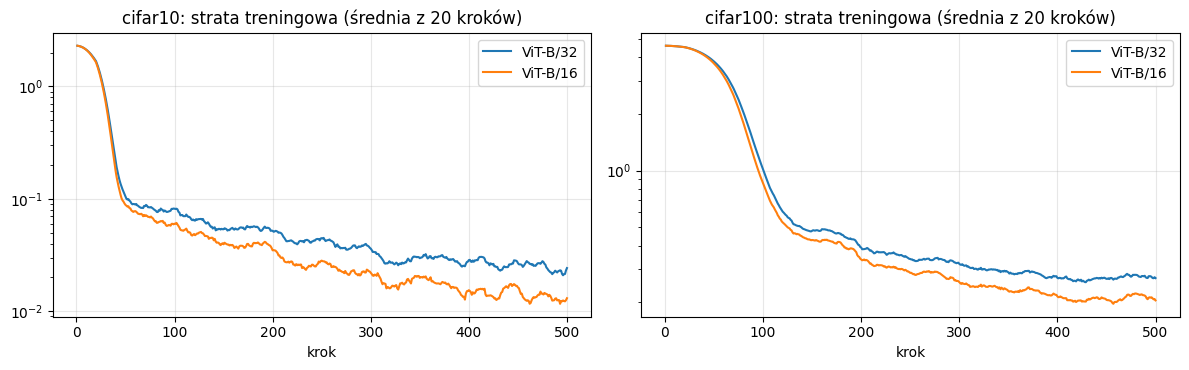

In [23]:
def ft_path(model_name, name, suffix=".pt"):
    return CACHE_DIR / f"ft_{slug(model_name)}_{name}{suffix}"


SCORES, HISTORIES = {}, {}
for model_name in MODELS:
    for name in DATASETS:
        weights, scores_file, history_file = (ft_path(model_name, name, suffix)
                                              for suffix in [".pt", "_scores.npy", "_history.csv"])
        if weights.exists() and scores_file.exists() and history_file.exists() and not RETRAIN:
            status = "wczytane"
        else:
            train_data = tuple(np.concatenate([DATA[name]["train"][i], DATA[name]["val"][i]]) for i in range(2))
            start = time.perf_counter()
            model, history, scores = fine_tune(model_name, name, BEST_LR[model_name, name], FT_STEPS,
                                               train_data, DATA[name]["test"])
            torch.save(model.state_dict(), weights)
            np.save(scores_file, scores)
            history.to_csv(history_file, index=False)
            status = f"wytrenowane w {(time.perf_counter() - start) / 60:.1f} min"
            del model
            free_memory()
        SCORES[model_name, name] = np.load(scores_file)
        HISTORIES[model_name, name] = pd.read_csv(history_file)
        accuracy = 100 * (SCORES[model_name, name].argmax(1) == DATA[name]["test"][1]).mean()
        print(f"{model_name:9s} {name:9s} lr={BEST_LR[model_name, name]:g}: test accuracy {accuracy:.2f}% ({status})")

fig, axes = plt.subplots(1, len(DATASETS), figsize=(12, 3.8))
for axis, name in zip(axes, DATASETS):
    for model_name in MODELS:
        history = HISTORIES[model_name, name]
        axis.plot(history["step"], history["loss"].rolling(20, min_periods=1).mean(), label=model_name)
    axis.set_title(f"{name}: strata treningowa (średnia z 20 kroków)")
    axis.set_xlabel("krok")
    axis.set_yscale("log")
    axis.grid(alpha=0.3)
    axis.legend()
plt.tight_layout()
plt.show()

## 9. Metryki

Z macierzy pomyłek liczymy dla każdej klasy precision $= TP/(TP+FP)$, recall $= TP/(TP+FN)$ i $F1 = 2PR/(P+R)$ i uśredniamy je po klasach (makro). Zbiory testowe są zbalansowane, więc recall makro jest równy accuracy (sprawdzamy to w kodzie). Niepewność accuracy szacujemy przedziałem ufności 95% metodą bootstrap (1000 losowań obrazów testowych ze zwracaniem); nie obejmuje on zmienności między powtórzeniami treningu.

In [24]:
from sklearn.metrics import precision_recall_fscore_support

rows, CONFUSIONS = [], {}
rng = np.random.default_rng(SEED)
for model_name in MODELS:
    for name in DATASETS:
        labels, predictions = DATA[name]["test"][1], SCORES[model_name, name].argmax(1)
        classes = len(DATA[name]["classes"])
        matrix = np.zeros((classes, classes), dtype=np.int64)
        np.add.at(matrix, (labels, predictions), 1)
        CONFUSIONS[model_name, name] = matrix

        tp = np.diag(matrix).astype(float)
        precision = np.divide(tp, matrix.sum(0), out=np.zeros(classes), where=matrix.sum(0) > 0)
        recall = tp / matrix.sum(1)
        f1 = np.divide(2 * precision * recall, precision + recall, out=np.zeros(classes), where=precision + recall > 0)
        reference = precision_recall_fscore_support(labels, predictions, average="macro", zero_division=0)[:3]
        assert np.allclose([precision.mean(), recall.mean(), f1.mean()], reference)

        correct = (predictions == labels).astype(float)
        low, high = np.percentile(correct[rng.integers(0, len(correct), (1000, len(correct)))].mean(1), [2.5, 97.5])
        assert np.isclose(recall.mean(), correct.mean())
        rows.append({"model": model_name, "zbiór": name, "accuracy [%]": 100 * correct.mean(),
                     "CI 95% [%]": f"{100 * low:.2f}-{100 * high:.2f}", "precision makro [%]": 100 * precision.mean(),
                     "recall makro [%]": 100 * recall.mean(), "F1 makro [%]": 100 * f1.mean()})

METRICS = pd.DataFrame(rows).set_index(["model", "zbiór"])
METRICS.round(2)

accuracy [%]   CI 95% [%]  precision makro [%]  \
model    zbiór                                                      
ViT-B/32 cifar10          98.56  98.33-98.79                98.56   
         cifar100         91.37  90.81-91.90                91.49   
ViT-B/16 cifar10          98.85  98.65-99.07                98.85   
         cifar100         92.78  92.25-93.25                92.85   

                   recall makro [%]  F1 makro [%]  
model    zbiór                                     
ViT-B/32 cifar10              98.56         98.56  
         cifar100             91.37         91.35  
ViT-B/16 cifar10              98.85         98.85  
         cifar100             92.78         92.76

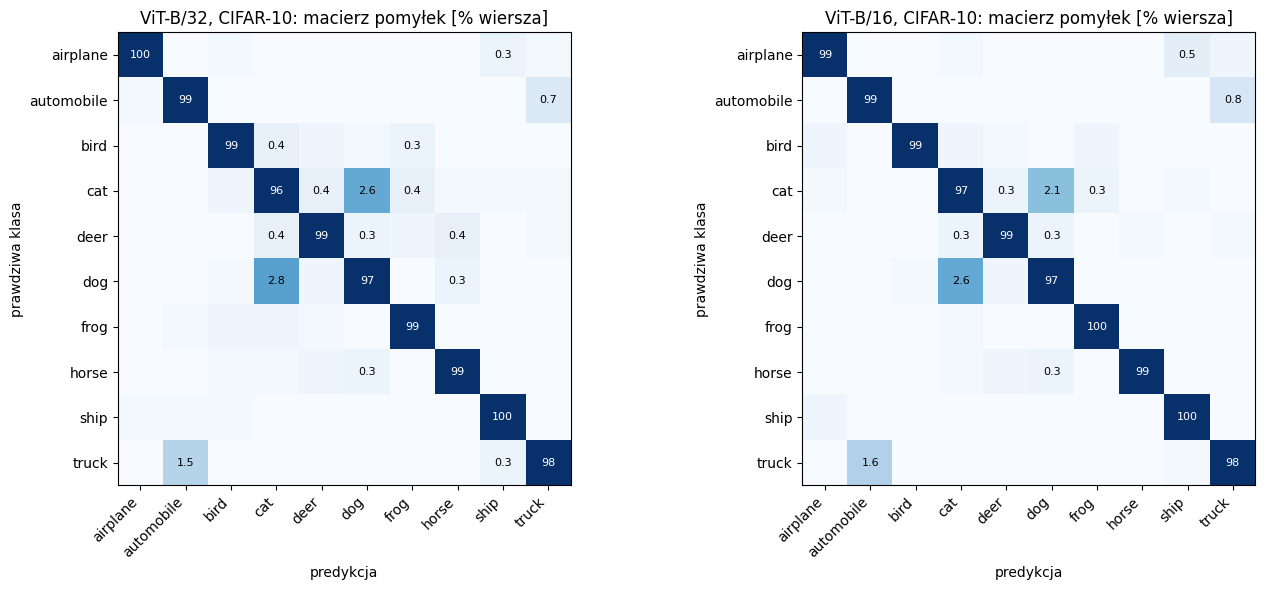

In [25]:
classes10 = DATA["cifar10"]["classes"]
fig, axes = plt.subplots(1, len(MODELS), figsize=(14, 6))
for axis, model_name in zip(axes, MODELS):
    matrix = CONFUSIONS[model_name, "cifar10"]
    normalized = 100 * matrix / matrix.sum(1, keepdims=True)
    axis.imshow(normalized, cmap="Blues", vmin=0, vmax=5)       # skala do 5%, żeby pomyłki były widoczne
    for i in range(10):
        for j in range(10):
            if i == j or normalized[i, j] >= 0.3:
                axis.text(j, i, f"{normalized[i, j]:.0f}" if i == j else f"{normalized[i, j]:.1f}", ha="center",
                          va="center", fontsize=8, color="white" if i == j or normalized[i, j] > 3 else "black")
    axis.set_xticks(range(10), classes10, rotation=45, ha="right")
    axis.set_yticks(range(10), classes10)
    axis.set_xlabel("predykcja")
    axis.set_ylabel("prawdziwa klasa")
    axis.set_title(f"{model_name}, CIFAR-10: macierz pomyłek [% wiersza]")
plt.tight_layout()
plt.show()

Fine-tuning daje ponad 98% accuracy na CIFAR-10 i ponad 91% na CIFAR-100. ViT-B/16 jest lepszy od ViT-B/32 na obu zbiorach, ale pewna jest tylko różnica na CIFAR-100, gdzie przedziały ufności się nie nakładają. Precision i F1 makro są prawie równe accuracy, więc błędy rozkładają się równomiernie między klasy. Najczęstsze pomyłki na CIFAR-10 to kot i pies oraz ciężarówka i samochód, czyli klasy podobne wizualnie przy 32×32 pikselach.

## 10. Porównanie z publikacją

Tabela 5 artykułu: modele pretrenowane na ImageNet-21k, fine-tuning przy 384 px, top-1 accuracy w %.

In [27]:
PAPER_TABLE_5 = {
    ("ViT-B/32", "cifar10"): 98.79, ("ViT-B/32", "cifar100"): 91.97,
    ("ViT-B/16", "cifar10"): 98.95, ("ViT-B/16", "cifar100"): 91.67,
}
COMPARISON = pd.DataFrame([
    {"model": model_name, "zbiór": name, "artykuł [%]": paper,
     "nasz wynik [%]": METRICS.loc[(model_name, name), "accuracy [%]"],
     "CI 95% [%]": METRICS.loc[(model_name, name), "CI 95% [%]"],
     "różnica [p.p.]": METRICS.loc[(model_name, name), "accuracy [%]"] - paper}
    for (model_name, name), paper in PAPER_TABLE_5.items()
]).set_index(["model", "zbiór"])
print(f"Średnia bezwzględna różnica: {COMPARISON['różnica [p.p.]'].abs().mean():.2f} p.p.")
COMPARISON.round(2)

Średnia bezwzględna różnica: 0.51 p.p.


artykuł [%]  nasz wynik [%]   CI 95% [%]  różnica [p.p.]
model    zbiór                                                             
ViT-B/32 cifar10         98.79           98.56  98.33-98.79           -0.23
         cifar100        91.97           91.37  90.81-91.90           -0.60
ViT-B/16 cifar10         98.95           98.85  98.65-99.07           -0.10
         cifar100        91.67           92.78  92.25-93.25            1.11

Wszystkie wyniki są w odległości od −0,6 do +1,1 p.p. od artykułu, mimo 20 razy krótszego treningu i niższej rozdzielczości. Na CIFAR-10 wynik artykułu mieści się w naszym przedziale ufności dla obu modeli. Na CIFAR-100 ViT-B/32 jest 0,6 p.p. poniżej, a ViT-B/16 1,1 p.p. powyżej artykułu, więc u nas ViT-B/16 wygrywa, a w artykule minimalnie przegrywa z ViT-B/32. Możliwe wyjaśnienie: przy 224 px ViT-B/32 ma tylko 50 tokenów, a przy 384 px u autorów 145, więc większy patch może bardziej tracić na niższej rozdzielczości. Tego nie sprawdzaliśmy; to punkt wyjścia do eksperymentów (sekcja 11).

## 11. Plan eksperymentów (K3)

**Pytanie badawcze:** Jak rozmiar patcha i rozdzielczość obrazu wpływają na dokładność, koszt obliczeniowy i odporność modelu ViT?

**Hipotezy:**

- **H1:** przy tej samej rozdzielczości i tym samym pretrainingu mniejszy patch daje wyższe accuracy i macro-F1, a koszt rośnie co najmniej proporcjonalnie do liczby tokenów.
- **H2:** przy tej samej liczbie tokenów (ViT-B/16 przy 224 px i ViT-B/32 przy 448 px, po 196 patchy) o wyniku decyduje liczba tokenów, a nie sam rozmiar patcha.
- **H3:** CIFAR ma natywnie 32 px, więc więcej tokenów bez nowej informacji (wyższa rozdzielczość wejścia) daje mniejszy zysk niż więcej informacji przy stałej liczbie tokenów.
- **H4:** modele z mniejszym patchem tracą więcej przy rozmyciu i szumie.

**Modele do porównania rozmiaru patcha:** ViT-B/32 i ViT-B/16 z artykułu; ViT-B/8, ViT-B/16 i ViT-B/32 w wersji AugReg (`timm`, ten sam przepis treningu dla trzech rozmiarów patcha); ViT-H/14 (patch 14, ale większy model, więc różnicy nie da się przypisać tylko patchowi).

| | Zmieniamy | Trzymamy stałe | Hipoteza |
|---|---|---|---|
| E1 | rozmiar patcha: 32 / 16 (artykuł), 32 / 16 / 8 (AugReg), 14 (ViT-H) | pretraining w grupie, 224 px | H1 |
| E2 | ViT-B/16 przy 224 px vs ViT-B/32 przy 448 px | liczba tokenów | H2 |
| E3 | rozdzielczość wejścia 160 / 224 / 288 / 384 px | model, obraz 32 px | H3 |
| E4 | obraz 32 px zmniejszony do 16 lub 8 px i przeskalowany do 224 px | liczba tokenów | H3 |
| E5 | szum i rozmycie gaussowskie, 5 poziomów, na obrazie 32 px | modele z E1 | H4 |

**Protokół i metryki:** CIFAR-10 i CIFAR-100; linear probe (zamrożony model, klasyfikator liniowy) dla wszystkich konfiguracji, fine-tuning jak w sekcji 8 dla wybranych; baseline: ViT-B/16 przy 224 px z sekcji 8. Accuracy, precision, recall i F1 makro, GFLOP, przepustowość, pamięć, spadek accuracy pod zakłóceniem.

**Powtórzenia i statystyka:** fine-tuning dla 3 ziaren (średnia i odchylenie), przedziały ufności bootstrap, test McNemara dla porównań na tych samych obrazach testowych.

**Źródła:** A. Dosovitskiy i in., ICLR 2021 (arXiv:2010.11929); [google-research/vision_transformer](https://github.com/google-research/vision_transformer); [`timm`](https://github.com/huggingface/pytorch-image-models); A. Krizhevsky, *Learning Multiple Layers of Features from Tiny Images*, 2009.